In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import random

data = pd.read_csv('../data/Task2/seeds_data.csv')

In [ ]:
data

In [ ]:
data.info()
data.describe()

In [2]:
data.Class.value_counts()

Class
1    70
2    70
3    70
Name: count, dtype: int64

In [3]:
def distance(a, b):
    return np.linalg.norm(a-b)

In [4]:
def standardize(data: pd.DataFrame):
    for col in data.columns:
        data[col] = (data[col] - data[col].mean()) / data[col].std()
    return data

# K-Means

In [5]:
class KMeans:
    class Cluster:
        def __init__(self, model: KMeans):
            self.model = model
            self.indices = list[int]()
        def size(self):
            return len(self.indices)
        def add(self, idx: int):
            self.indices.append(idx)
        def retrieve(self):
            return self.model.data[self.indices,:]
        def reset(self):
            self.indices.clear()
        def mean(self):
            return self.retrieve().mean(axis=0)
        def wcss(self):
            mean = self.mean()
            data = self.retrieve()
            return sum(distance(x, mean)**2 for x in data)

    def __init__(self, data: pd.DataFrame, k=3):
        self.data = data.to_numpy()
        self.k = k

    def run(self) -> list[Cluster]:
        """ Implement the k-means clustering algorithm
        Returns: the resultant set of clusters
        """
        # random initial centroids
        centroids = self.data[random.sample(range(self.data.shape[0]), self.k)]
        clusters = [self.Cluster(self) for _ in range(self.k)]
        while True:
            old_centroids = centroids
            for c in clusters:
                c.reset()
            for idx in range(self.data.shape[0]):
                # compute distance from every cluster's centroid
                dists = list(map(lambda centroid: distance(self.data[idx], centroid), centroids))
                # add to the closest cluster
                clusters[np.argmin(dists)].add(idx)
            centroids = np.array([c.mean() for c in clusters])
            if np.all(old_centroids == centroids):
                break
        return clusters

    def cluster(self, N=5) -> list[Cluster]:
        """ Try clustering multiple times to get the set of clusters with the least WCSS
        Args:
            N: number of attempts
        Returns: The best set of clusters
        """
        wcss = list()
        list_of_clusters = list()
        for i in range(N):
            clusters = self.run()
            wcss.append(sum(c.wcss() for c in clusters))
            list_of_clusters.append(clusters)
        return list_of_clusters[np.argmin(wcss)]

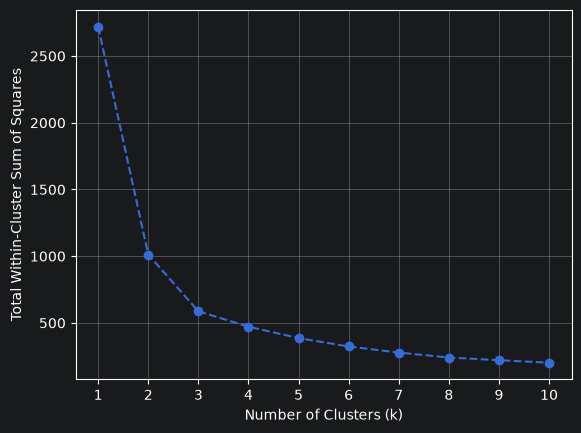

In [6]:
km_model = KMeans(data.drop(columns=['Class']))
y = list()
for k in range(1, 11):
    km_model.k = k
    wcss = sum(c.wcss() for c in km_model.cluster())
    y.append(wcss)
plt.plot(range(1, 11), y, marker='o', linestyle='--')
plt.xticks(range(1, 11))
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Total Within-Cluster Sum of Squares')
plt.grid()
plt.show()

In [7]:
km_model = KMeans(data.drop(columns=['Class']))
km_clusters = km_model.cluster()

for c in km_clusters:
    print('Size:', c.size())
    print('Cluster labels:', data.Class[c.indices].to_list())
    print('Cluster center: ', c.mean())
    print()

Size: 72
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3]
Cluster center:  [14.64847222 14.46041667  0.87916667  5.56377778  3.27790278  2.64893333
  5.19231944]

Size: 61
Cluster labels: [1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Cluster center:  [18.72180328 16.29737705  0.88508689  6.20893443  3.72267213  3.60359016
  6.06609836]

Size: 77
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
Cluster center:  [11.96441558 13.27480519  0.8522      5.22928571  2.87292208  4.7

# DBSCAN

In [8]:
class DBSCAN:
    class Point:
        def __init__(self, model: DBSCAN, idx: int):
            """ Construct a point
            Args:
                model: the parent DBSCAN model
                idx: the index of the point in the model data
            Other Attributes:
                neighbors: a list of neighboring points
                visited: whether the point has visited. Post run, falsity signifies noise.
            """
            self.model = model
            self.idx = idx
            self.neighbors = list[DBSCAN.Point]()
            self.visited = False

        def is_core(self):
            """ Check if the point is a core point
            Returns: True if neighbor count >= min_samples. False means it's a border point or noise.
            """
            return len(self.neighbors) >= self.model.min_samples

        def classify(self):
            """ Find neighboring points within eps """
            for pt in self.model.points:
                if distance(self.model.data[pt.idx], self.model.data[self.idx]) <= self.model.eps:
                    self.neighbors.append(pt)

        def visit(self):
            """ Mark the point as visited """
            self.visited = True

    class Cluster:
        def __init__(self, model: DBSCAN):
            """ Construct a cluster
            Args:
                model: the parent DBSCAN model
            Other Attributes:
                points: a list of constituent points
            """
            self.model = model
            self.points = list[DBSCAN.Point]()

        def size(self):
            """ Returns: the number of points in the cluster """
            return len(self.points)

        def add(self, pt: DBSCAN.Point):
            """ Add a point to the cluster """
            self.points.append(pt)

        def expand(self, root: DBSCAN.Point):
            """ Recursively expand the cluster 'til there are no more core points.
            Border points are added but not used for expansion. Noise is left unvisited.
            Args:
                root: the root point
            """
            for pt in root.neighbors:
                if not pt.visited:
                    pt.visit()
                    self.add(pt)
                    if pt.is_core():
                        self.expand(pt)

        def retrieve(self):
            """ Retrieve the cluster data
            Returns: a subdataset of the model data
            """
            return self.model.data[[pt.idx for pt in self.points],:]

    def __init__(self, data: pd.DataFrame, eps, min_samples):
        """ Construct a DBSCAN model and classify the points
        Args:
            data: the dataset
            eps: epsilon, the radial limit of neighbors to a point
            min_samples: minimum neighboring points required for a point to be a core point
        Other Attributes:
            points: a list of the DBSCAN.Point form of the examples
        """
        self.data = standardize(data).to_numpy()
        self.eps = eps
        self.min_samples = min_samples
        self.points = [self.Point(self, idx) for idx in range(self.data.shape[0])]
        for pt in self.points:
            pt.classify()

    def run(self):
        """ Implement the DBSCAN clustering algorithm
        Returns: the resultant set of clusters and a dummy noise cluster
        """
        clusters = []
        for pt in self.points:
            if not pt.visited and pt.is_core():
                pt.visit()
                cluster = self.Cluster(self)
                cluster.add(pt)
                cluster.expand(pt)
                clusters.append(cluster)
        noise = self.Cluster(self)
        for pt in self.points:
            if not pt.visited:
                noise.add(pt)
        return clusters, noise


In [9]:
"""
General rule: min_samples >= D + 1 => min_samples >= 8
Between 10 and 14 gives 3 clusters. I'm setting 10 'cause it gives the least noise.
"""
MIN_SAMPLES = 10

X = standardize(data.drop(columns=['Class']))

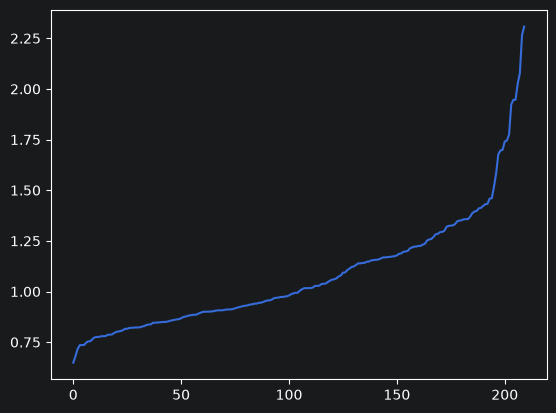

In [10]:
from sklearn.neighbors import NearestNeighbors

nb = NearestNeighbors(n_neighbors=MIN_SAMPLES)
dists, indices = nb.fit(X).kneighbors(X)
dists = np.sort(dists[:, -1])

"""
The elbow point of the plot signifies the boundary between dense clusters and noise.
It's around 1.4 and setting eps to 1.4 minimizes noise but produces only one cluster 'cause apparently the data doesn't really have defined boundaries between clusters.
eps = 0.9 outputs low misclassification and three clusters as expected at the cost of significant noise.
"""

# plot the sorted distances of every point from its 'min_samples'-th neighbor
plt.plot(dists)
plt.show()

In [11]:
db_model = DBSCAN(data.drop(columns=['Class']), .9, MIN_SAMPLES)
db_clusters, noise = db_model.run()

for c in db_clusters:
    print('Size:', c.size())
    print('Cluster labels:', data.Class[sorted([pt.idx for pt in c.points])].to_list())
    print()

print(f'{len(db_clusters)} clusters formed')
print(f'{noise.size()} noise points')

Size: 39
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2]

Size: 60
Cluster labels: [1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

Size: 35
Cluster labels: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

3 clusters formed
76 noise points


 # PCA & Evaluation

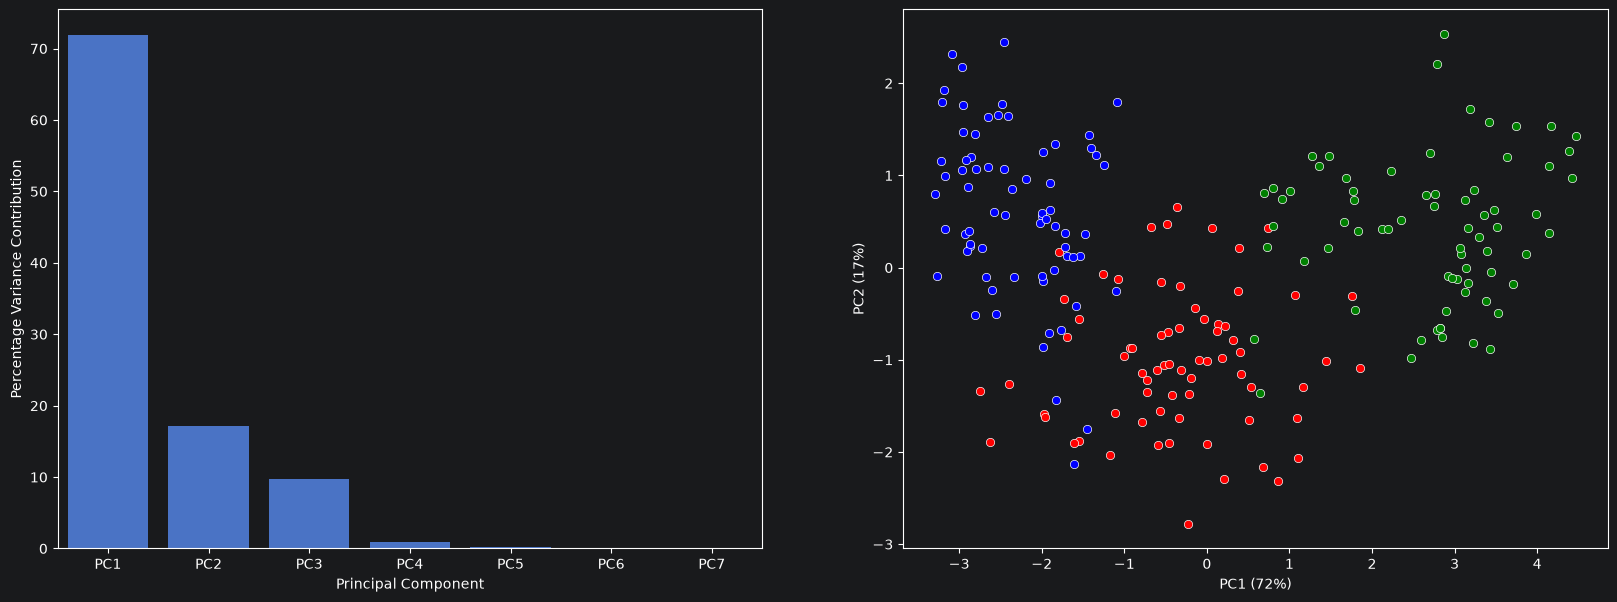

In [12]:
X = standardize(data.drop(columns=['Class'])).to_numpy()
cov = X.T @ X / (X.shape[0]-1)    # covariance matrix

eig_val, eig_vec = np.linalg.eig(cov)
eig_val, eig_vec = eig_val.real, eig_vec.real
var_sum = eig_val.sum()     # sum of variances

fig, ax = plt.subplots(1, 2, figsize=(20, 7))
sns.barplot(x=[f'PC{i}' for i in range(1, 8)], y=np.sort(eig_val, descending=True)/var_sum*100, ax=ax[0])
ax[0].set_xlabel('Principal Component')
ax[0].set_ylabel('Percentage Variance Contribution')

idx1 = np.argmax(eig_val)
pc1, pc1_var = eig_vec[:, idx1], eig_val[idx1]
eig_val, eig_vec = np.delete(eig_val, idx1), np.delete(eig_vec, idx1, axis=1)
idx2 = np.argmax(eig_val)
pc2, pc2_var = eig_vec[:, idx2], eig_val[idx2]

W = np.stack([pc1, pc2], axis=1)    # projection matrix
X_pca = X @ W

colors = ['red', 'green', 'blue']
for i in range(3):
    sns.scatterplot(x=X_pca[data.Class==i+1, 0], y=X_pca[data.Class==i+1, 1], color=colors[i], ax=ax[1])
ax[1].set_xlabel(f'PC1 ({pc1_var/var_sum*100:.0f}%)')
ax[1].set_ylabel(f'PC2 ({pc2_var/var_sum*100:.0f}%)')
plt.show()

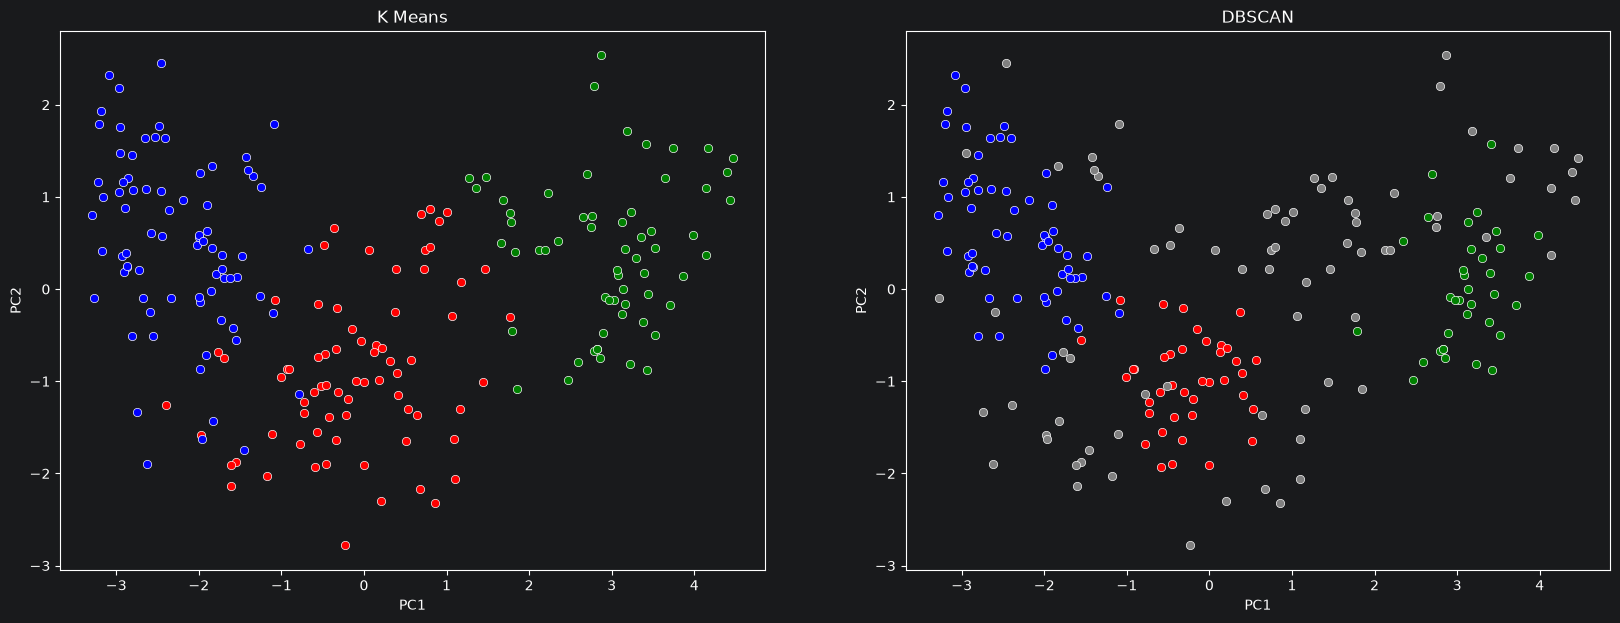

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
for c in km_clusters:
    y = data.Class[c.indices].mode()[0]
    sns.scatterplot(x=X_pca[c.indices, 0], y=X_pca[c.indices, 1], color=colors[y-1], ax=ax[0])
ax[0].set_title('K Means')
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
for c in db_clusters:
    indices = [pt.idx for pt in c.points]
    y = data.Class[indices].mode()[0]
    sns.scatterplot(x=X_pca[indices, 0], y=X_pca[indices, 1], color=colors[y-1], ax=ax[1])
indices = [pt.idx for pt in noise.points]
sns.scatterplot(x=X_pca[indices, 0], y=X_pca[indices, 1], color='gray', ax=ax[1])
ax[1].set_title('DBSCAN')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
plt.show()

In [14]:
from sklearn.metrics import adjusted_rand_score

km_labels = np.empty(X.shape[0])
for c in km_clusters:
    y = data.Class[c.indices].mode()[0]
    km_labels[c.indices] = y
db_labels = np.empty(X.shape[0])
for c in db_clusters:
    indices = [pt.idx for pt in c.points]
    y = data.Class[indices].mode()[0]
    db_labels[indices] = y
indices = [pt.idx for pt in noise.points]
db_labels[indices] = -1

print('K-Means ARI: ', adjusted_rand_score(data.Class, km_labels))
print('DBSCAN ARI: ', adjusted_rand_score(data.Class, db_labels))

K-Means ARI:  0.7166198557361053
DBSCAN ARI:  0.42632600288785033
